In [1]:
import sys
import os
sys.path.append(os.path.abspath(".."))  # чтобы импортировать utils.py
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils import fetch_df

# Настройка графиков
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [2]:
query_funnel = """
SELECT
    toStartOfMonth(reg_date) AS month,
    sum(registered) AS registered,
    sum(verified) AS verified,
    sum(activated) AS activated,
    sum(got_product) AS got_product
FROM neobank_marts.dm_funnel
GROUP BY month
ORDER BY month
"""
df_funnel = fetch_df(query_funnel)
df_funnel

,month,registered,verified,activated,got_product
0,2024-01-01,1327,247,247,420
1,2024-02-01,1659,346,346,485
2,2024-03-01,2217,530,530,713
3,2024-04-01,2761,717,717,858
4,2024-05-01,3318,907,907,988
5,2024-06-01,3876,1161,1161,1022
6,2024-07-01,4420,1405,1405,224
7,2024-08-01,4977,1644,1644,84
8,2024-09-01,5535,1835,1835,0
9,2024-10-01,6079,2165,2165,0


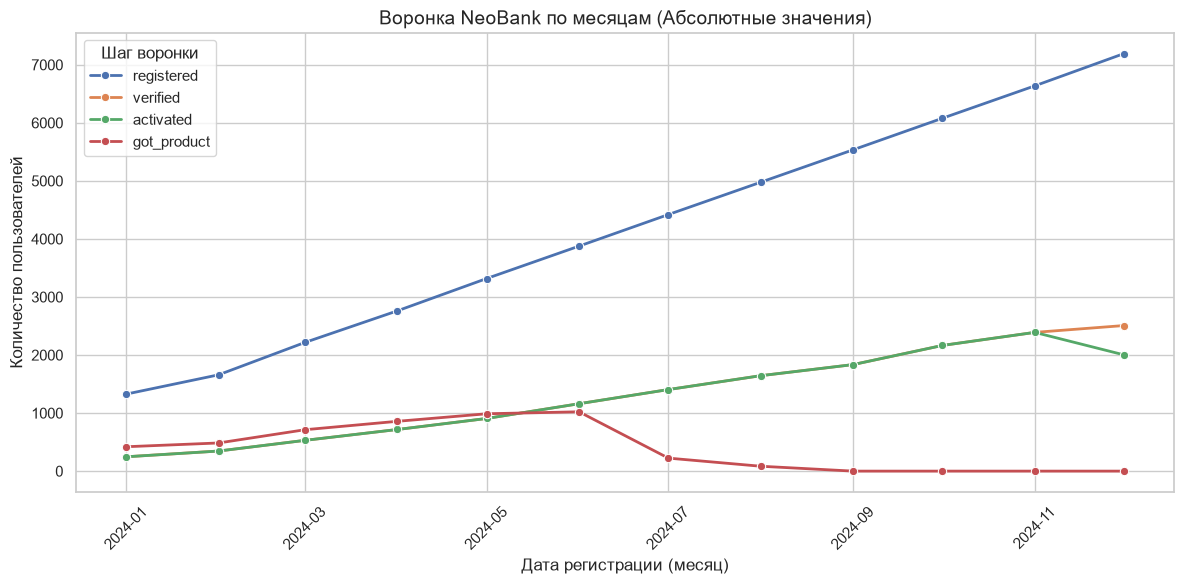

In [3]:
# Переводим в формат для графика (long format)
df_plot = df_funnel.melt(id_vars=["month"], 
                         value_vars=["registered", "verified", "activated", "got_product"],
                         var_name="step", value_name="users")

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_plot, x="month", y="users", hue="step", marker="o", linewidth=2)
plt.title("Воронка NeoBank по месяцам (Абсолютные значения)", fontsize=14)
plt.xlabel("Дата регистрации (месяц)", fontsize=12)
plt.ylabel("Количество пользователей", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Шаг воронки")
plt.tight_layout()
plt.show()

In [4]:
# Берем только завершенные транзакции за первую половину года, чтобы не перегружать память
query_tx = """
SELECT
    tx_id,
    client_id,
    amount,
    tx_type,
    category,
    tx_date
FROM neobank_staging.stg_transactions
WHERE status = 'completed' AND toMonth(tx_date) <= 6
LIMIT 100000
"""
df_tx = fetch_df(query_tx)
print(f"Загружено {len(df_tx)} транзакций")
df_tx.head()

Загружено 38810 транзакций


,tx_id,client_id,amount,tx_type,category,tx_date
0,49155,9677,4442.0,purchase,utilities,2024-06-15
1,49165,9679,1368.0,transfer,<NA>,2024-06-05
2,49166,9679,1089.0,purchase,entertainment,2024-06-09
3,49167,9679,1250.0,purchase,groceries,2024-06-07
4,49168,9679,1647.0,purchase,groceries,2024-06-06


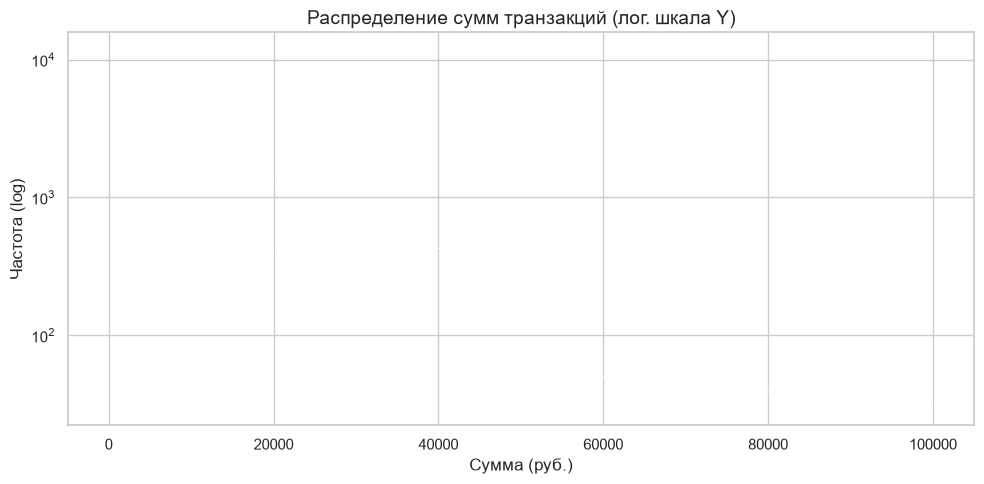

In [5]:
plt.figure(figsize=(10, 5))
# Используем log_scale, так как суммы транзакций имеют длинный хвост (много мелких, мало крупных)
sns.histplot(df_tx[df_tx["amount"] > 0]["amount"], bins=50, log_scale=(False, True))
plt.title("Распределение сумм транзакций (лог. шкала Y)", fontsize=14)
plt.xlabel("Сумма (руб.)", fontsize=12)
plt.ylabel("Частота (log)", fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\Dima\AppData\Local\Temp\ipykernel_16568\1312827606.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette="viridis")


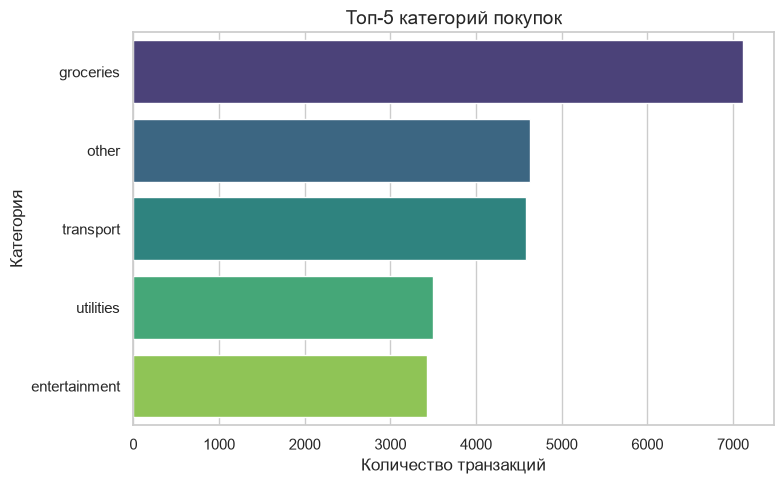

In [6]:
top_categories = df_tx[df_tx["tx_type"] == "purchase"]["category"].value_counts().head(5)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_categories.values, y=top_categories.index, palette="viridis")
plt.title("Топ-5 категорий покупок", fontsize=14)
plt.xlabel("Количество транзакций", fontsize=12)
plt.ylabel("Категория", fontsize=12)
plt.tight_layout()
plt.show()